In [4]:
import matplotlib.pyplot as plt
import matplotlib
import csv
import numpy as np
import pandas as pd
import os
import scipy.stats as ss
import rmgpy.constants
from rmgpy.reaction import Reaction
from rmgpy.species import Species
from rmgpy.molecule import Molecule
from rmgpy.kinetics.arrhenius import Arrhenius
from rmgpy.data.rmg import RMGDatabase
from rmgpy import settings
from rmgpy.chemkin import load_chemkin_file
%matplotlib inline

In [15]:
color_dictionary = { 'CF2s': (214, 39, 39),
 'CF3r': (85, 85, 85),
 'PF2alkylr': (128, 128, 0),
 'PF3alkylr': (26, 190, 207),
 'PF4alkylr': (70, 130, 180),
 'PF5alkylr': (140, 87, 75),
 'PF6alkylr': (227, 119, 194),
 'PF7-1-H': (45, 160, 45),
 'PF7-1-ene': (255, 127, 15) ,
 'PF7alkylr': (149, 103, 189),
 'PF8lactone': (30, 120, 180)}    

marker_dictionary_with_lines={'PF8lactone': ':o', 
'PF7alkylr':  '--^', 
'PF4alkylr': '--d',
'PF6alkylr': '--h',
'PF5alkylr': '--v',
'PF3alkylr': '--s',  
'CF2(s)': ':v',
'CF3r': '--*',    
'PF2alkylr': '--o', 
'PF7-1H': ':d', 
'PF7ene': ':s'}

just_marker_dictionaries = {'PF8lactone': 'o', 
'PF7alkylr':  '^', 
'PF4alkylr': 'd',
'PF6alkylr': 'h',
'PF5alkylr': 'v',
'PF3alkylr': 's',  
'CF2s': 'v',
'CF3r': '*',    
'PF2alkylr': 'o', 
'PF7-1-H': 'd', 
'PF7-1-ene': 's'}



labels = [
    
'PF8acid <=> HF + PF8lactone',    
'PF8acid <=> CO2 + HF + PF7-1-ene',    
'PF8acid <=> CO2 + PF7-1-H',    
'PF8acid <=> CF2s + PF7acid',    
'PF8acid <=> PF7alkylr + rCOOH',    
'PF8acid <=> PF6alkylr + rPF2acid',   
'PF8acid <=> PF5alkylr + rPF3acid',    
'PF8acid <=> PF4alkylr + rPF4acid',    
'PF8acid <=> PF3alkylr + rPF5acid',    
'PF8acid <=> PF2alkylr + rPF6acid',    
'PF8acid <=> CF3r + rPF7acid']    

In [6]:
def linear_regression(x_data, y_data): 
    lr = ss.linregress(x_data, y_data)    
    return lr

def get_parameters_from_linear_regression(lr): 
    
    neg_Ea_over_R = lr.slope #slope 
    Ea_in_Joules_per_mole = -neg_Ea_over_R * rmgpy.constants.R #R in Joules per mole-Kelvin (J / mol / K)
    
    lnA = lr.intercept
    A = np.e**lnA# units of s^-1
    
    return A, Ea_in_Joules_per_mole 

def make_rmg_reaction(lr, label):
    
    A, Ea = get_parameters_from_linear_regression(lr)
    
    #get the products from the NCSU thermo library
    species_involved = label.replace('+','').replace('PF8acid <=> ','').split('  ')
    
    products_involved = []
    for spec_label in species_involved:
        
        string_to_add=spec_label+'\n'
        
        if spec_label == 'CF2s':
            spec_label = 'CF2(s)'
            
        if spec_label == 'PF7-1-H':
            spec_label = 'PF7-1H'
            
        if spec_label == 'PF7-1-ene':
            spec_label = 'PF7ene'
            
        if spec_label == 'rCOOH':
            spec_label = 'HOCOr'            
            
        if spec_label[0]=='r':
            spec_label = spec_label[1:] + 'r' #put the 'r' in the back 
            
        
        thermo_entry = NCSU_lib.entries[spec_label]
        adj_list=thermo_entry.item.to_adjacency_list()
        products_involved.append(Species(molecule=[Molecule().from_adjacency_list(adj_list)]))
        
    #reactant will always be PFOA
    PFOA_spec = Species(molecule=[Molecule().from_adjacency_list(NCSU_lib.entries['PF8acid'].item.to_adjacency_list())])
    
    
    reaction = Reaction(label = label, reactants = [PFOA_spec], products = products_involved, kinetics = Arrhenius(A = (A, 's^-1'), n=0, Ea = (Ea, 'J/mol'))) 
    return reaction 

def make_rmg_reaction_with_thermo(lr, label):
    
    A, Ea = get_parameters_from_linear_regression(lr)
    
    #get the products from the NCSU thermo library
    species_involved = label.replace('+','').replace('PF8acid <=> ','').split('  ')
    
    products_involved = []
    for spec_label in species_involved:
        
        string_to_add=spec_label+'\n'
        
        if spec_label == 'CF2s':
            spec_label = 'CF2(s)'
            
        if spec_label == 'PF7-1-H':
            spec_label = 'PF7-1H'
            
        if spec_label == 'PF7-1-ene':
            spec_label = 'PF7ene'
            
        if spec_label == 'rCOOH':
            spec_label = 'HOCOr'            
            
        if spec_label[0]=='r':
            spec_label = spec_label[1:] + 'r' #put the 'r' in the back 
            
        
        thermo_entry = NCSU_lib.entries[spec_label]
        adj_list=thermo_entry.item.to_adjacency_list()
        products_involved.append(Species(molecule=[Molecule().from_adjacency_list(adj_list)], thermo=thermo_entry.data))
        
    #reactant will always be PFOA
    PFOA_spec = Species(molecule=[Molecule().from_adjacency_list(NCSU_lib.entries['PF8acid'].item.to_adjacency_list())], thermo=NCSU_lib.entries['PF8acid'].data)
    
    
    reaction = Reaction(label = label, reactants = [PFOA_spec], products = products_involved, kinetics = Arrhenius(A = (A, 's^-1'), n=0, Ea = (Ea, 'J/mol'))) 
    return reaction 
                        
def get_rate_data_from_rmg(reaction):

    rate_coeffs_for_rmg_reaction = []
    for inv_T in inverse_temps: 
        temp = 1000/inv_T
        rate_coeff = reaction.get_rate_coefficient(temp)
        rate_coeffs_for_rmg_reaction.append(rate_coeff)
    return np.array(rate_coeffs_for_rmg_reaction)

In [15]:
NCSU_lib.entries['H'].data

NASA(polynomials=[NASAPolynomial(coeffs=[2.5,0,0,0,0,25473.7,-0.446683], Tmin=(200,'K'), Tmax=(6000,'K')), NASAPolynomial(coeffs=[2.5,0,0,0,0,25473.7,-0.446683], Tmin=(6000,'K'), Tmax=(6000,'K'))], Tmin=(200,'K'), Tmax=(6000,'K'))

In [14]:
plt.rcParams['axes.labelsize'] = 18
plt.rcParams['xtick.labelsize'] = 15
plt.rcParams['ytick.labelsize'] = 15
plt.rcParams['figure.autolayout'] = True
matplotlib.rcParams['font.family'] = 'serif'

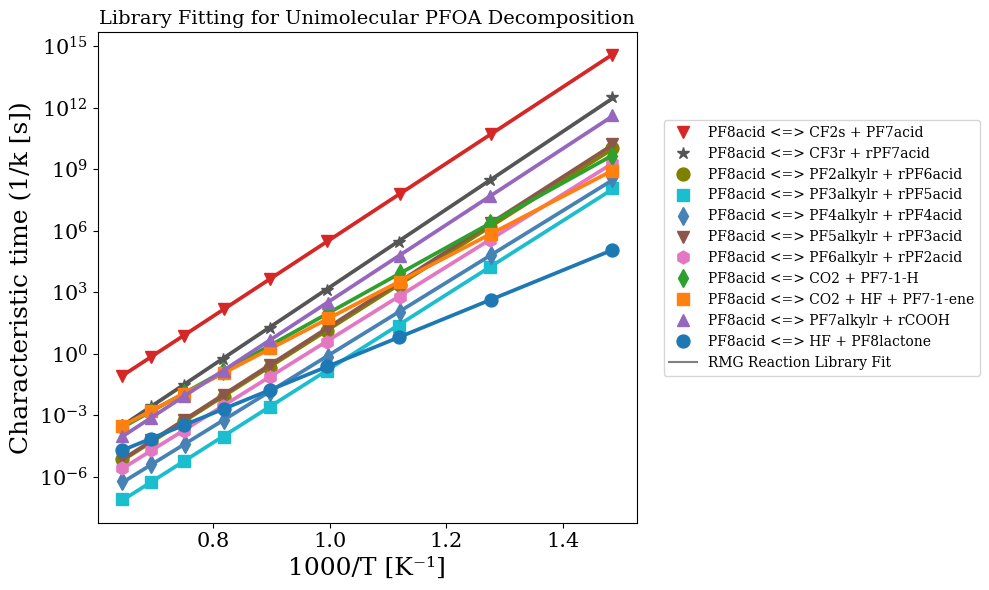

In [44]:
rmg_reactions_for_library = [] #for saving RMG reactions to

csv_files = [file for file in os.listdir('./PFOAdecomp_figure_data/') if '.csv' in file]

fig = plt.figure(figsize = (10, 6))
ax1 = fig.add_subplot(111)

ax1.set_yscale('log')
ax1.set_title('Library Fitting for Unimolecular PFOA Decomposition', fontsize=14)
ax1.set_ylabel('Characteristic time (1/k [s])')
ax1.set_xlabel('1000/T [K\u207b\u00b9]')


# fig2 = plt.figure()
# ax2 = fig2.add_subplot(111)

# ax2.set_title('Unimolecular Reactions involving PFOA')
# ax2.set_ylabel('ln(k)')
# ax2.set_xlabel('1/T [K-1]')

def ticks(y, pos):
    return r'$e^{:.0f}$'.format(np.log(y))

#ax2.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(ticks))


#original Figure 1 
for file in csv_files:
    dataframe = pd.read_csv(f'./PFOAdecomp_figure_data/{file}')
    
    inverse_temps = dataframe.iloc[:,0]
    inverse_k = dataframe.iloc[:, 1] 
    
    _1_over_T = np.array(inverse_temps)/1000 #converting to 1/T
    lnk = np.log(1/np.array(inverse_k)) #converting 1/k to lnk
    
    
    file_label = file.replace('.csv', '')
    
    label = [l for l in labels if file_label in l][0]
    
    normalized_color_numbers = [c/255 for c in color_dictionary[file_label]]
    
    # if 'lactone' in label:
    #     line = ''
    # else: 
    #     line = '-'
    
    marker = just_marker_dictionaries[file_label]
    ax1.plot(inverse_temps, inverse_k, marker, markersize=9.3, color = normalized_color_numbers,  label = label)
    # ax2.plot(_1_over_T, lnk, line, color = normalized_color_numbers,  label = label)
    
    # ax1.legend(loc=(1,0.3))
    # ax2.legend(loc=(1,0.3))
    
    
    #back calculate rate
    lr = linear_regression(_1_over_T, lnk)
    rmg_reaction = make_rmg_reaction(lr, label)
    rate_coeffs_for_rmg_reaction = get_rate_data_from_rmg(rmg_reaction)
    # ax1.plot( inverse_temps, 1/rate_coeffs_for_rmg_reaction, 'o', markerfacecolor='none', color = normalized_color_numbers, label = label+' (RMG)')
    
    rmg_reactions_for_library.append(rmg_reaction)
    
    
    #what if we also make sure to add in thermo of species...
    rmg_reaction_thermo = make_rmg_reaction_with_thermo(lr, label)
    rate_coeffs_for_rmg_reaction_thermo = get_rate_data_from_rmg(rmg_reaction_thermo)
    ax1.plot( inverse_temps, 1/rate_coeffs_for_rmg_reaction_thermo, '-', linewidth=2.7, markerfacecolor='none', color = normalized_color_numbers)


ax1.plot([],[], '-', color='gray', label = 'RMG Reaction Library Fit')   
ax1.legend(loc=(1.05,0.3))

#convert to a ln(K) v 1/T 

fig.savefig('./lib_fitting_PFOA_decomp.pdf')



Write an RMG formatted library for the RMG reaction data 

In [8]:
thermolibs = ['NCSU_2025_revised']

database = RMGDatabase()
database.load(
    path = settings['database.directory'],
    thermo_libraries = thermolibs,  # Can add others if necessary
    kinetics_families = [],
    reaction_libraries = ['PFOA_unimolecular_decomp'],
    kinetics_depositories = [],
)

In [9]:
NCSU_lib = database.thermo.libraries['NCSU_2025_revised']

In [15]:

dictionary_text = []

library_text = []




#get the species labels from the RMG thermo library from westmoreland 

count=0
for r in rmg_reactions_for_library:
    
    
    #generate the dictionary.txt 
    species_involved = r.label.replace('+','').replace('<=>','').split('  ')
    
    for spec_label in species_involved:
        
        string_to_add=spec_label+'\n'
        
        if spec_label == 'CF2s':
            spec_label = 'CF2(s)'
            
        if spec_label == 'PF7-1-H':
            spec_label = 'PF7-1H'
            
        if spec_label == 'PF7-1-ene':
            spec_label = 'PF7ene'
            
        if spec_label == 'rCOOH':
            spec_label = 'HOCOr'            
            
        if spec_label[0]=='r':
            spec_label = spec_label[1:] + 'r' #put the 'r' in the back 
            
        
        thermo_entry = NCSU_lib.entries[spec_label]

        string_to_add+=thermo_entry.item.to_adjacency_list()
        
        if string_to_add not in dictionary_text: 
            dictionary_text.append(string_to_add)
            
            
    #generate the library reactions.py 
    count+=1
    
    library_entry_string = f"""entry(
    index = {count},
    label = "{r.label}",
    degeneracy = 1.0,
    kinetics = {r.kinetics},
)

    
    """
    
    library_text.append(library_entry_string)
    
        
            
            
    


In [138]:
#test: can we load in the library? 

database = RMGDatabase()
database.load(
    path = settings['database.directory'],
    thermo_libraries = [],  # Can add others if necessary
    kinetics_families = [],
    reaction_libraries = ['PFOA_unimolecular_decomp'],
    kinetics_depositories = [],
)



In [38]:
for key, value in database.kinetics.libraries['PFOA_unimolecular_decomp'].entries.items():
    display(value.item)
    display(value.data)

KeyError: 'PFOA_unimolecular_decomp'

In [147]:
for rxn in rmg_reactions_for_library:
    print(rxn.kinetics.Ea.value/4.184) #converting from J/mol to cal/mol

85206.62673850294
86822.85187798756
82599.40129027801
82497.22031924773
80215.69117951716
83428.63390074029
80949.95699682625
72162.64422402509
67711.75440687919
84974.84306735928
53139.185952576074


In [14]:
#how did the reactions actually end up in the RMG model?
mech_path = '../fix_reg_spec_in_core/lower_tolerance/skeleton_mech_ABP2/chemkin/chem_annotated_copy.inp'
dictionary_path = '../fix_reg_spec_in_core/lower_tolerance/skeleton_mech_ABP2/chemkin/species_dictionary.txt'
mech_spec, mech_reactions = load_chemkin_file(mech_path, dictionary_path=dictionary_path)

PFOA(36) <=> CF2(s)(17) + PF7acid(35)
PFOA(36) <=> CF3r(19) + PF7acidr(94)
PFOA(36) <=> PF2alkylr(108) + PF6acidr(93)
PFOA(36) <=> PF3alkylr(109) + PF5acidr(92)
PFOA(36) <=> PF4alkylr(110) + PF4acidr(91)
PFOA(36) <=> PF3acidr(90) + PF5alkylr(111)
PFOA(36) <=> PF2acidr(89) + PF6alkylr(112)
PFOA(36) <=> CO2(13) + PF7-1H(63)
PFOA(36) <=> HF(11) + CO2(13) + PF7ene(69)
PFOA(36) <=> HOCOr(14) + PF7alkylr(113)
PFOA(36) <=> HF(11) + PF8lactone(88)


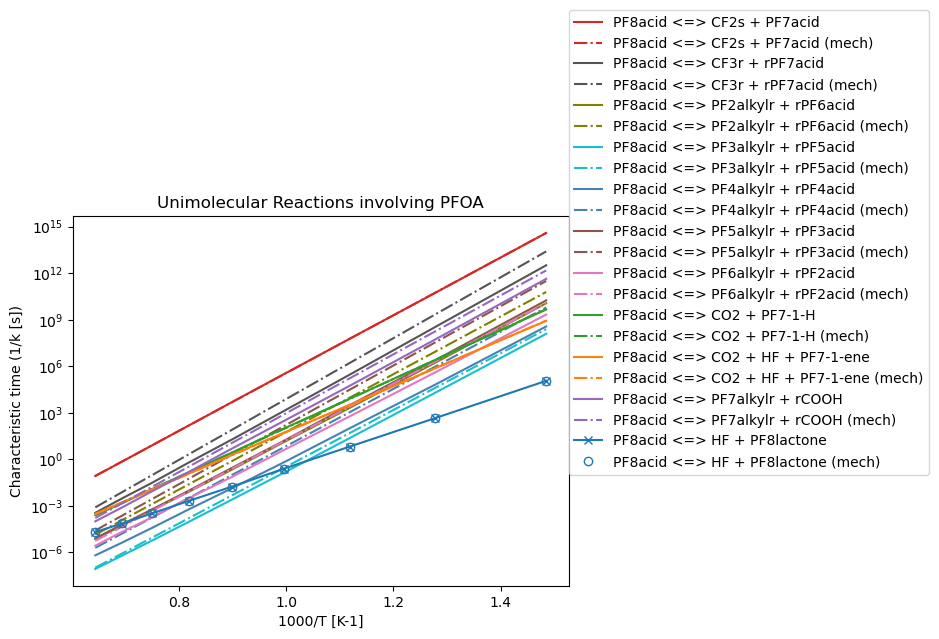

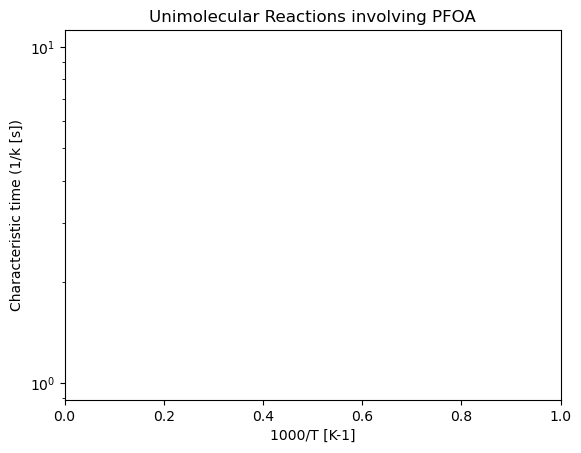

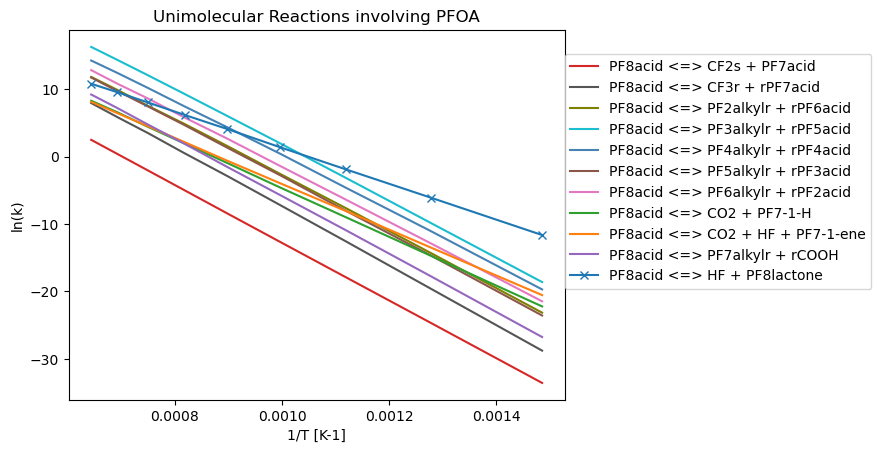

In [18]:
rmg_reactions_for_library = [] #for saving RMG reactions to

csv_files = [file for file in os.listdir('./PFOAdecomp_figure_data/') if '.csv' in file]

fig = plt.figure()
ax1 = fig.add_subplot(111)

ax1.set_yscale('log')
ax1.set_title('Unimolecular Reactions involving PFOA')
ax1.set_ylabel('Characteristic time (1/k [s])')
ax1.set_xlabel('1000/T [K-1]')

fig = plt.figure()
ax3 = fig.add_subplot(111)

ax3.set_yscale('log')
ax3.set_title('Unimolecular Reactions involving PFOA')
ax3.set_ylabel('Characteristic time (1/k [s])')
ax3.set_xlabel('1000/T [K-1]')

fig2 = plt.figure()
ax2 = fig2.add_subplot(111)

ax2.set_title('Unimolecular Reactions involving PFOA')
ax2.set_ylabel('ln(k)')
ax2.set_xlabel('1/T [K-1]')


def ticks(y, pos):
    return r'$e^{:.0f}$'.format(np.log(y))

#ax2.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(ticks))


#original Figure 1 
for file in csv_files:
    dataframe = pd.read_csv(f'./PFOAdecomp_figure_data/{file}')
    
    inverse_temps = dataframe.iloc[:,0]
    inverse_k = dataframe.iloc[:, 1] 
    
    _1_over_T = np.array(inverse_temps)/1000 #converting to 1/T
    lnk = np.log(1/np.array(inverse_k)) #converting 1/k to lnk
    
    
    file_label = file.replace('.csv', '')
    
    label = [l for l in labels if file_label in l][0]
    
    normalized_color_numbers = [c/255 for c in color_dictionary[file_label]]
    
    if 'lactone' in label:
        line = '-x'
    else: 
        line = '-'
    
    ax1.plot(inverse_temps, inverse_k, line, color = normalized_color_numbers,  label = label)
    ax2.plot(_1_over_T, lnk, line, color = normalized_color_numbers,  label = label)
    
    # ax1.legend(loc=(1,0.3))
    # ax2.legend(loc=(1,0.3))
    
    
    # back calculate rate
    lr = linear_regression(_1_over_T, lnk)
    rmg_reaction = make_rmg_reaction(lr, label)
    rate_coeffs_for_rmg_reaction = get_rate_data_from_rmg(rmg_reaction)
    #ax1.plot( inverse_temps, 1/rate_coeffs_for_rmg_reaction, 'o', markerfacecolor='none', color = normalized_color_numbers, label = label+' (RMG)')
    
    rmg_reactions_for_library.append(rmg_reaction)
    
    
    #find the matching reaction from our crafted RMG reaction that ended up in the model
    for rr in mech_reactions:
        if rr.is_isomorphic(rmg_reaction):
            if 'unimolecular' in rr.family:
                print(rr)

                if 'lactone' in label:
                    line = 'o'
                else: 
                    line = '-.'
                
                rate_coeffs_for_mech_reaction = get_rate_data_from_rmg(rr)
                ax1.plot( inverse_temps, 1/rate_coeffs_for_mech_reaction, line, markerfacecolor='none', color = normalized_color_numbers, label = label+' (mech)')

    ax1.legend(loc=(1,0.3))
    ax2.legend(loc=(1,0.3))

#convert to a ln(K) v 1/T 